# 03 — VIX futures carry backtest (2013–present)

Three variants of `strategies.vix_carry.VIXCarryStrategy` through the
event-driven engine (real CBOE settlements, transaction costs, margin):

1. **naive always-short** — no exits, no gate, 1x notional. The XIV replica.
2. **regime-filtered** — calm to enter, genuine crisis to exit (VIX-30 breaker,
   deep backwardation), acceleration halves exposure. Still 1x notional.
3. **filtered + vol-targeted** — same gates, position sized to a 15% annual
   vol budget with a 2x notional cap.

Re-derive with `python -m scripts.run_vix_carry`. **Read the conclusion before
the charts:** this is a negative-result notebook done honestly — front-month
VX carry post-2013 with survival constraints and real costs earns roughly cash.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vrp_lab.config import load_config, PROCESSED, REPORTS
cfg = load_config()
%config InlineBackend.figure_format = "retina"


In [2]:
eq = pd.read_csv(PROCESSED / "equity_curves.csv", index_col=0, parse_dates=True)
results = pd.read_csv(REPORTS / "vix_carry_results.csv", index_col=0)
results.round(3)

,naive_always_short,regime_filtered,filtered_vol_targeted
ann_return,-1.000,-0.051,0.020
ann_vol,0.551,0.535,0.109
sharpe,0.087,0.135,-0.013
sortino,0.102,0.167,-0.016
calmar,-0.906,-0.059,0.088
max_drawdown,-1.104,-0.853,-0.226
dd_duration_days,3102.000,1643.000,907.000
dd_recovery_days,NaN,NaN,365.000
cvar_95,-0.086,-0.099,-0.020
cvar_99,-0.191,-0.176,-0.037


**The naive column is the exhibit**: −100% annualized (ruin on 2018-02-05, equity through zero — precisely XIV's fate that afternoon), skew −11.6, kurtosis 346, 2,120 margin-breach days. A Sharpe printed on top of that distribution would be meaningless.

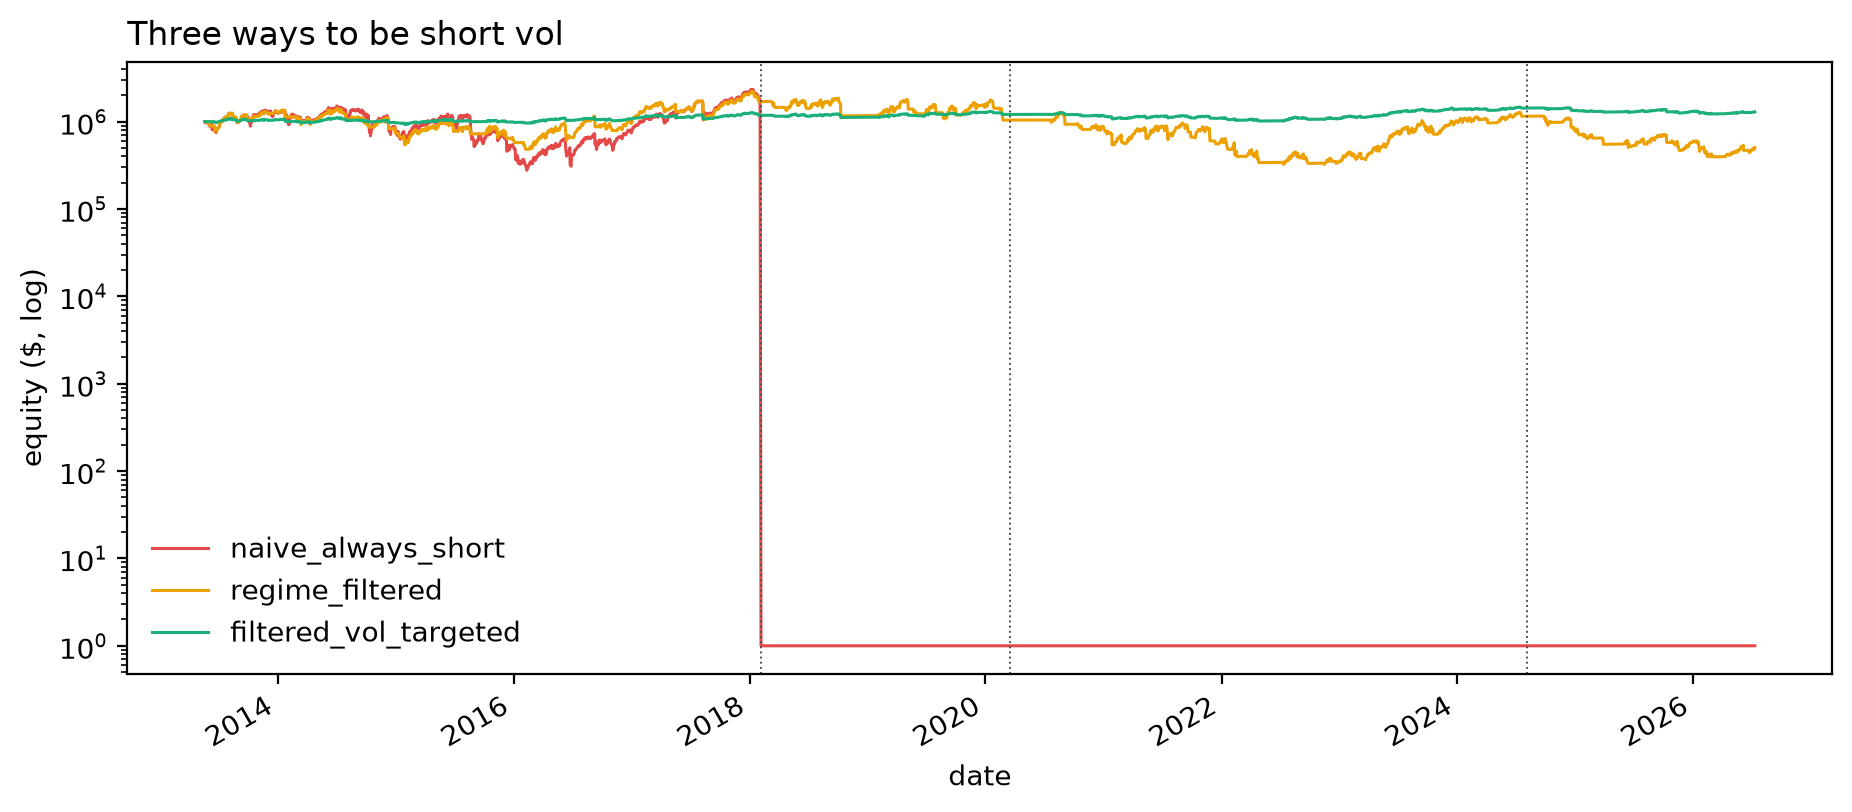

In [3]:
ax = eq.clip(lower=1).plot(figsize=(11, 4.5), logy=True, lw=1.1,
        color=["#e34948", "#eda100", "#1baf7a"])
ax.set_ylabel("equity ($, log)"); ax.set_title("Three ways to be short vol", loc="left")
for i, ev in enumerate(["2018-02-05", "2020-03-16", "2024-08-05"]):
    ax.axvline(pd.Timestamp(ev), color="#52514e", lw=0.7, ls=":")
ax.legend(frameon=False);

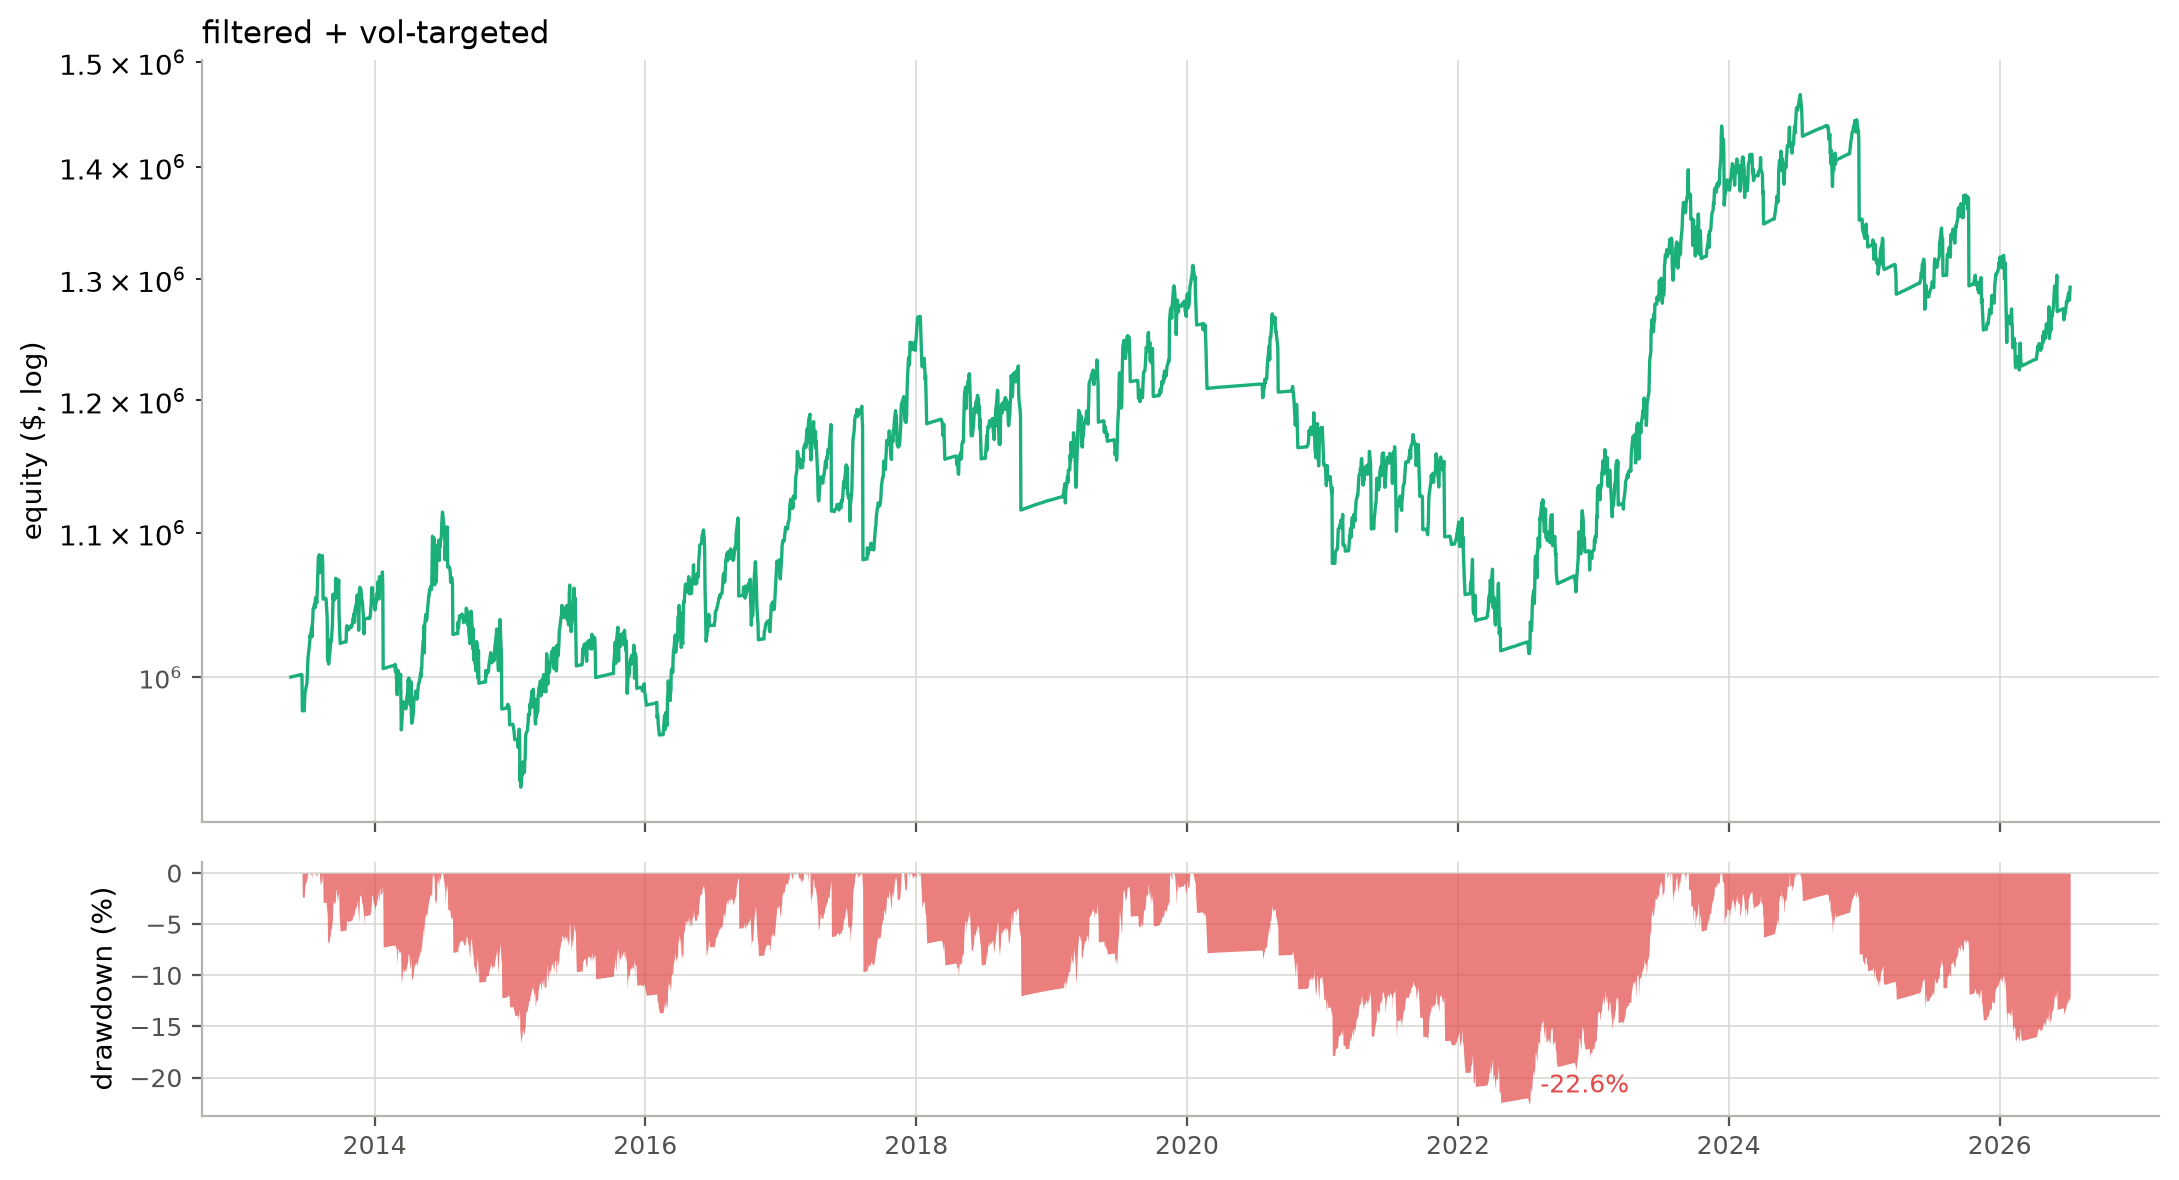

In [4]:
from vrp_lab.visualization.plots import plot_equity_drawdown, plot_rolling_sharpe, plot_monthly_heatmap
main = eq["filtered_vol_targeted"]
plot_equity_drawdown(main, title="filtered + vol-targeted");

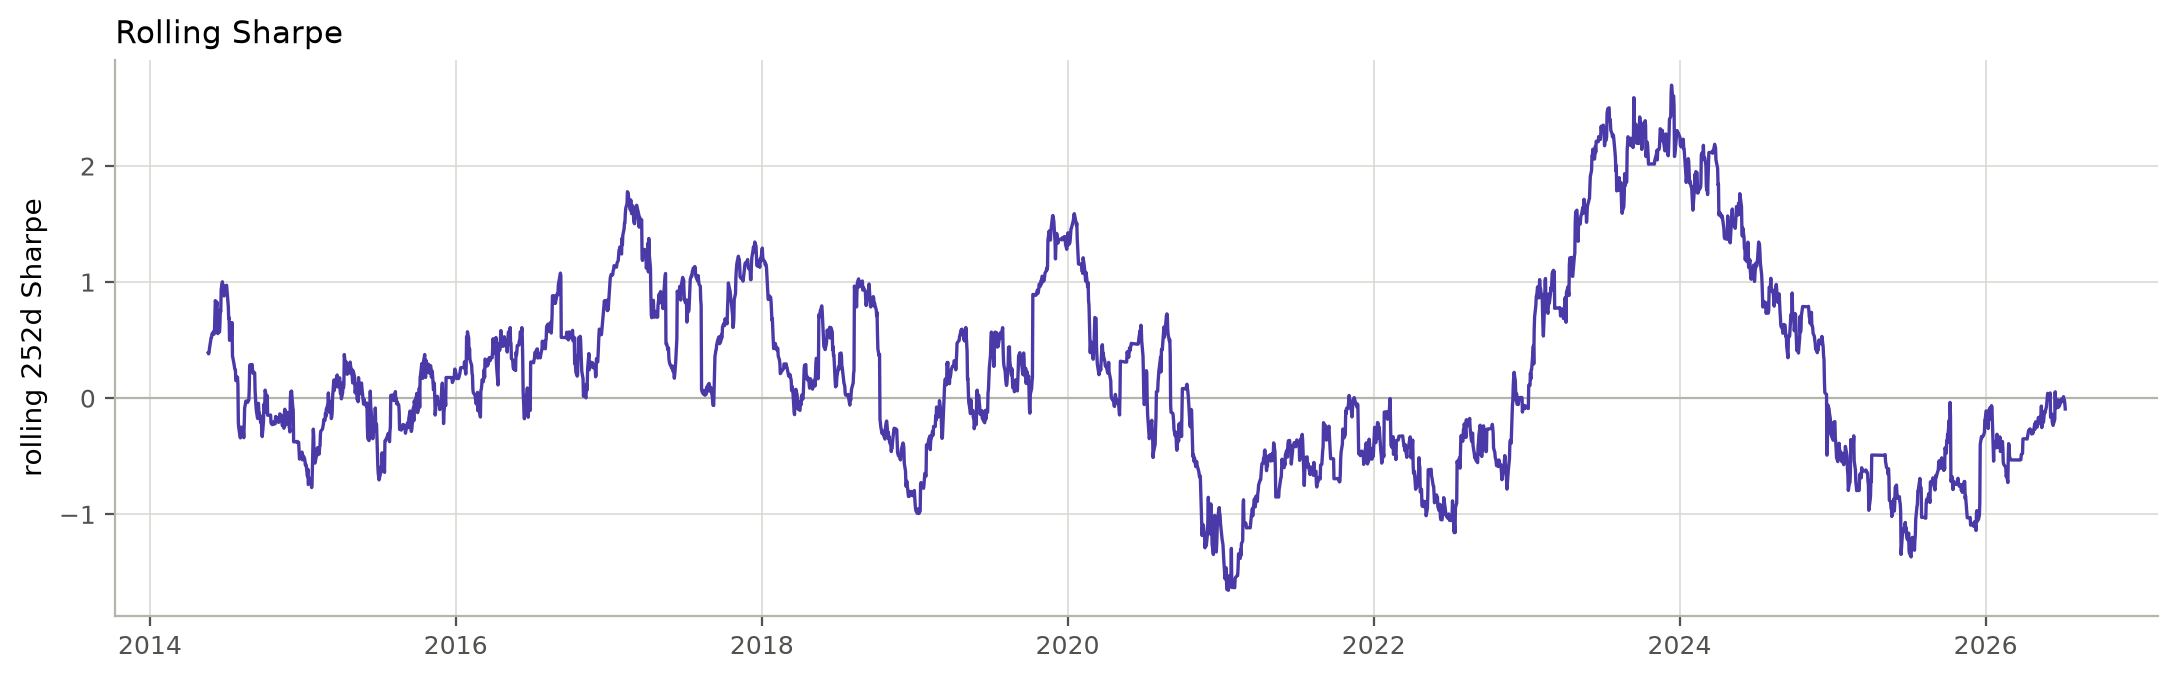

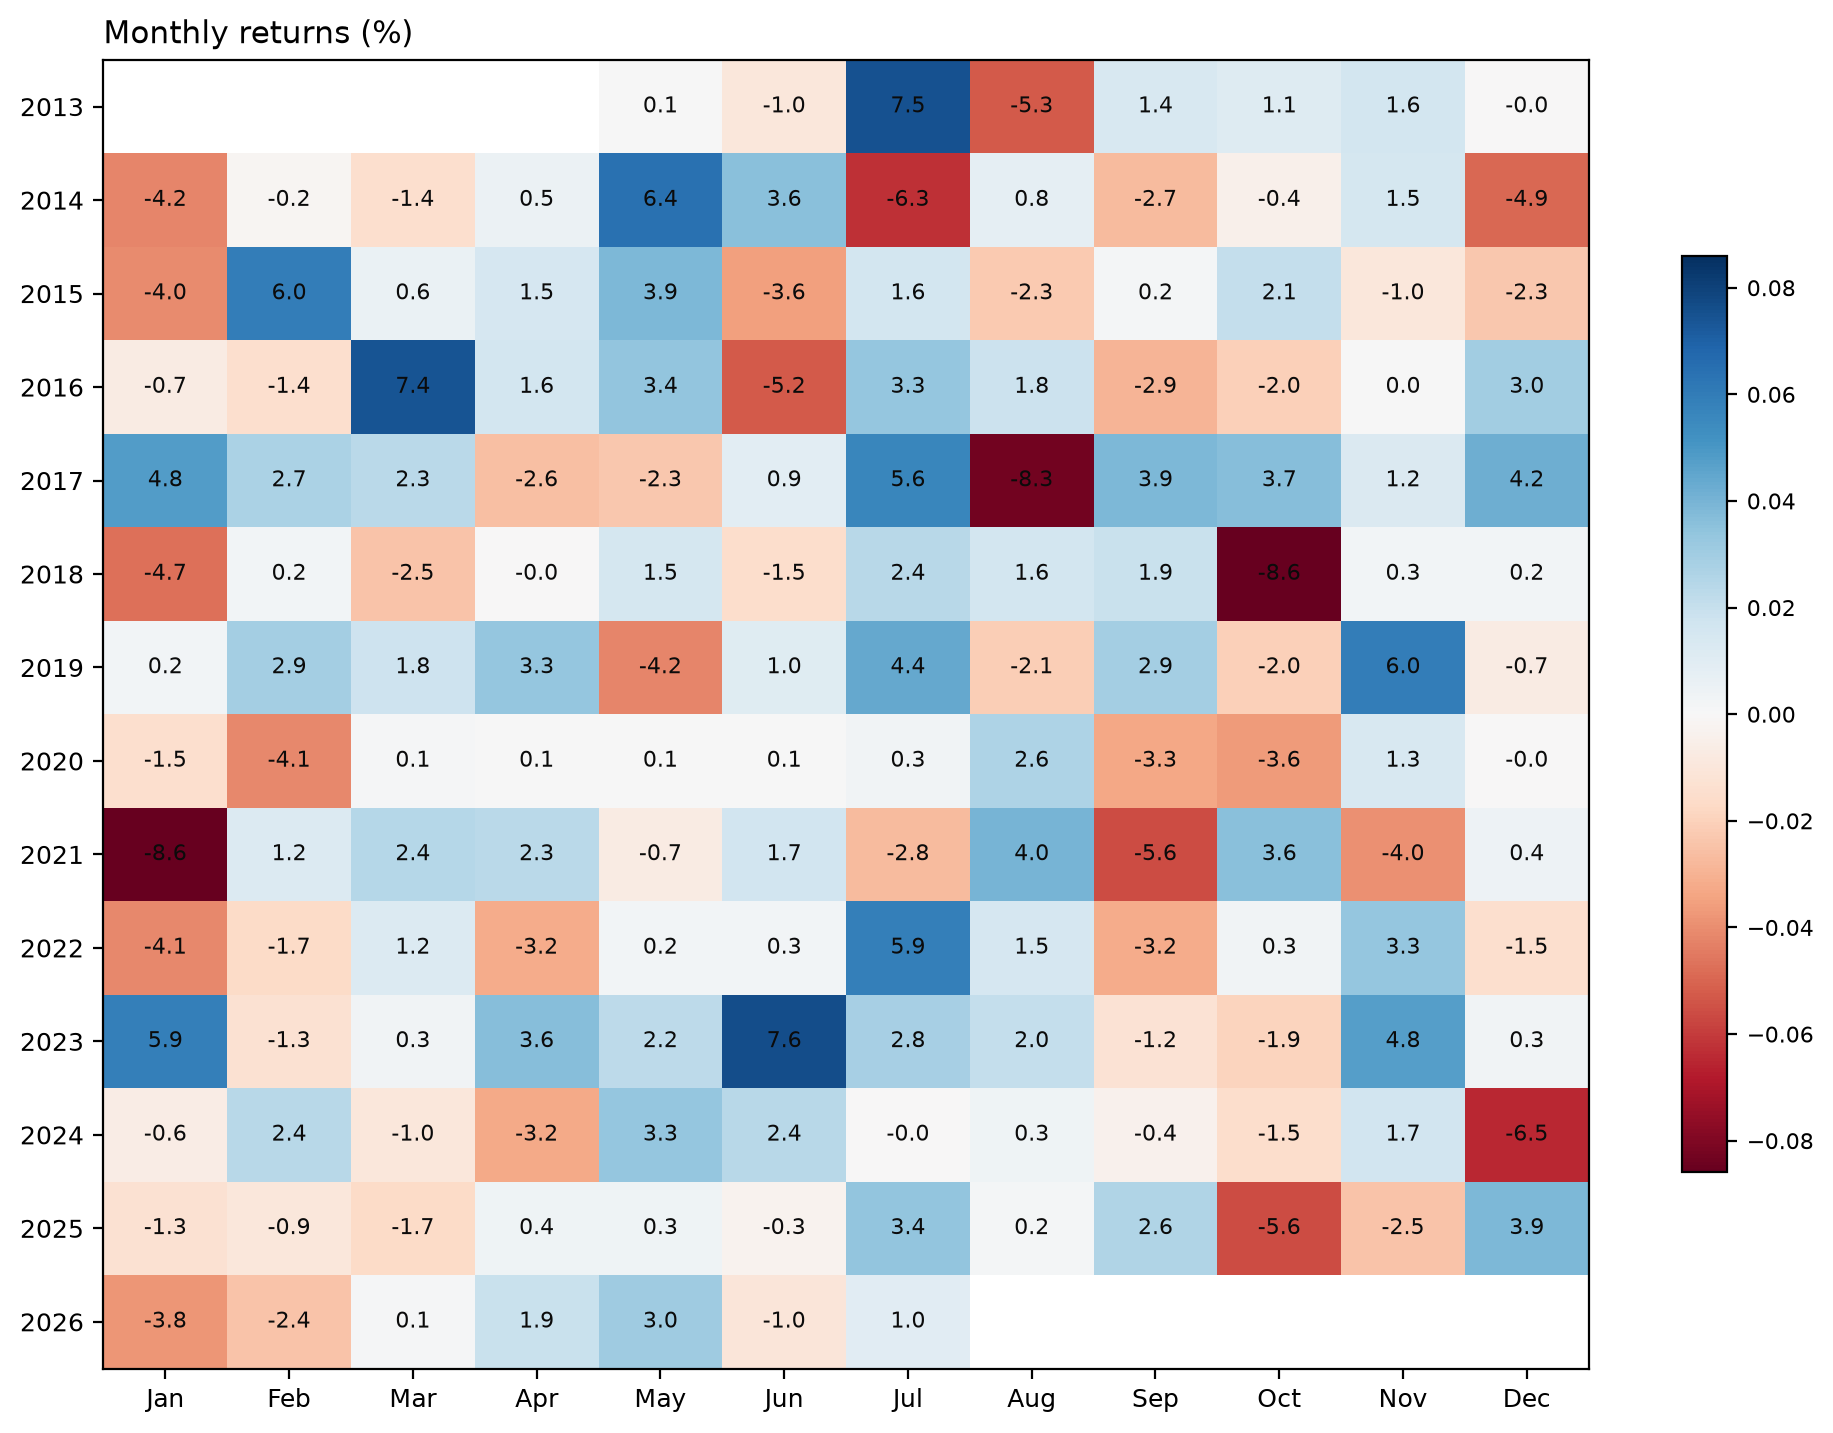

In [5]:
rets = main.pct_change().dropna()
plot_rolling_sharpe(rets);
plot_monthly_heatmap(rets);

## P&L by term-structure regime

In [6]:
from vrp_lab.data import cboe
from vrp_lab.volatility.term_structure import build_curve, classify_regime
vix_full = cboe.pull_vix_history()["close"]
curve = build_curve(cboe.pull_vx_curve("2013-01-01"), vix_full)
reg = classify_regime(curve).reindex(rets.index).fillna("mixed")
pnl_by_regime = rets.groupby(reg).agg(["mean", "std", "count"])
pnl_by_regime["ann_mean_%"] = (100 * 252 * pnl_by_regime["mean"]).round(2)
pnl_by_regime

,mean,std,count,ann_mean_%
ts_regime,,,,
backwardation,-0.002363,0.008824,711,-59.55
contango,0.000883,0.006022,2461,22.26
mixed,-0.001171,0.006262,135,-29.52


## Honest conclusions

* The premium measured in notebook 01 is real; **capturing it via front-month
  futures is another matter.** Costs (~0.035 pts + commission per side, 24+
  legs/year), spike losses, and the survival-mandated exits consume most of it
  post-2013.
* Every risk control has a price: the VIX-30 circuit breaker covers near spike
  highs by construction. Removing it is how you become the naive column.
* Vol targeting cuts CVaR-99 from −17.6% to −3.7% and max DD from −85% to
  −23% — the distribution improves far more than the mean degrades.
* What would help: longer-dated tenors (VX4–VX7 carry with less gamma),
  entry conditioning on the VRP z-score, and the 2006–2012 sample this free
  data source can't reach (contango was fatter pre-2013).